<a href="https://colab.research.google.com/github/ivannarch865/ivannarichards5to/blob/main/Class7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
file_path='https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/reg_data.csv'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn import linear_model
import seaborn as sns

In [ ]:
df=pd.read_csv(file_path)
df

,Gender,Age,Place,Weight,Company,Education,JoinYear,Salary
0,Male,58.0,NaN,70.7,GM,Master,2006.0,74862.0
1,Female,56.0,1.0,65.9,BMW,Master,2021.0,60652.0
2,Male,54.0,2.0,88.9,BMW,PhD,2011.0,65058.0
3,Male,26.0,3.0,63.2,Tesla,PhD,2016.0,46284.0
4,Male,49.0,4.0,60.9,GM,Master,2012.0,60945.0
...,...,...,...,...,...,...,...,...
145,Male,32.0,4.0,69.5,GM,NaN,2013.0,56127.0
146,Male,29.0,2.0,NaN,Tesla,Master,2018.0,51189.0
147,Male,57.0,2.0,81.4,BMW,PhD,NaN,NaN
148,Male,59.0,3.0,51.0,BMW,Bachelor,NaN,65600.0


In [ ]:
df.Place.unique()

array([nan,  1.,  2.,  3.,  4.])

What is the Salary of Female person with age 56, from Place 1, with weight 65.9, working BMW, with Masters education, joined 2021?


In [ ]:
df.isnull().any()

,0
Gender,True
Age,True
Place,True
Weight,True
Company,True
Education,True
JoinYear,True
Salary,True


What is the Salaru of person with age 56?

`Salary=b0+b1*Age`

In [ ]:
favs=['Salary', 'Age']
ndf=df[favs].dropna()
ndf.isnull().any()

,0
Salary,False
Age,False


Option1: machine learning way

In [ ]:
X=pd.DataFrame(ndf["Age"])
y=ndf["Salary"]

lm=linear_model.LinearRegression()
model_lm=lm.fit(X,y)
model_lm

LinearRegression()

In [ ]:
age_coef=model_lm.coef_[0]
age_coef

np.float64(474.8831135412749)

In [ ]:
b0= model_lm.intercept_
b0

np.float64(41324.85017590291)

In [ ]:
model_lm.score(X,y)

0.6364727494094164

In [ ]:
age= int(input('Enter age to find salary'))


Enter age to find salary56


In [ ]:
print(f'Salary of a person with Age {age} ist\t', float(b0+age_coef*age))

Salary of a person with Age 56 ist	 67918.3045342143


Option 2: Statisticians way

In [ ]:
reg_eqn= 'Salary ~ Age'
modelA=sm.OLS.from_formula(reg_eqn, data=ndf).fit()

modelA.summary()



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     220.6
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.82e-29
Time:                        00:45:56   Log-Likelihood:                -1250.0
No. Observations:                 128   AIC:                             2504.
Df Residuals:                     126   BIC:                             2510.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4.132e+04   1348.047     30.655      0.000    3.87e+04     4.4e+04
Age          474.8831     31.973     14.853      0.000     411.610     538.156
==============================================================================
Omnibus:                       10.694   Durbin-Watson:                   1.811
Prob(Omnibus):                  0.005   Jarque-Bera (JB):               11.906
Skew:                           0.559   Prob(JB):                      0.00260
Kurtosis:                       3.992   Cond. No.                         151.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
modelA.params

,0
Intercept,41324.850176
Age,474.883114


In [ ]:
modelA.resid

,0
0,5993.929239
1,-7266.304534
2,-1910.538307
3,-7387.811128
4,-3649.122739
...,...
144,-1506.590285
145,-394.109809
146,-3907.460469
148,-3742.953875


In [ ]:
modelA.fittedvalues

,0
0,68868.070761
1,67918.304534
2,66968.538307
3,53671.811128
4,64594.122739
...,...
144,62694.590285
145,56521.109809
146,55096.460469
148,69342.953875


In [ ]:
study=[df['Age'], df['Salary'], modelA.fittedvalues, modelA.resid]
pd.cotact(study,axis=1)

AttributeError: module 'pandas' has no attribute 'cotact'

Text(45, 65050, 'Salary=b0+b1*Age')

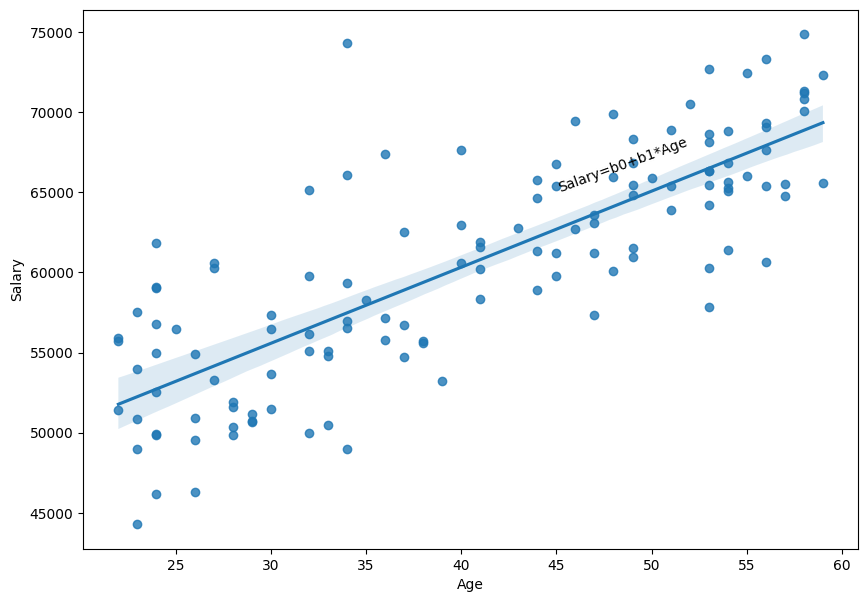

In [ ]:
plt.figure(figsize=(10,7))
ax =sns.regplot(x='Age',
             y='Salary',
             data=ndf)

ax.set(xlabel='Age',ylabel='Salary')

ax.text(45,65050, 'Salary=b0+b1*Age', rotation=20, size='medium')

# 2.1What is the Salary of a Female with Age 56?

# 2.2Whar is the Salary of Male with Age 56?

In [ ]:
favs=['Salary', 'Age', 'Gender']

ndf2=df[favs].dropna()
ndf2.isnull().any()